# Level 3 - Task 1: Random Forest Classifier
**Codveda ML Internship**

**Goal:** predict customer churn with a Random Forest, tune it, evaluate it properly, and find which features matter most.

**Dataset:** Codveda's churn data - `churn_train.csv` (2,666 customers) for training and tuning, `churn_test.csv` (667 customers) kept untouched for the final test.

**Steps:** 1) preprocess, 2) tune hyperparameters, 3) cross-validate and evaluate, 4) feature importance.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

DATA_DIR = "../data"  # NB
train = pd.read_csv(f"{DATA_DIR}/churn_train.csv"); test = pd.read_csv(f"{DATA_DIR}/churn_test.csv")
print("Train:", train.shape, "| Test:", test.shape, "| Churn rate (train): %.1f%%" % (train["Churn"].mean() * 100))

drop_cols = ["State", "Total day charge", "Total eve charge", "Total night charge", "Total intl charge"]
y_train = train["Churn"].astype(int); y_test = test["Churn"].astype(int)
X_train = train.drop(columns=drop_cols + ["Churn"]); X_test = test.drop(columns=drop_cols + ["Churn"])
X_train["Area code"] = X_train["Area code"].astype(str); X_test["Area code"] = X_test["Area code"].astype(str)
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

# Trees do not need scaling, so we only one-hot encode the categories
pre = ColumnTransformer([("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols)],
                        remainder="passthrough", verbose_feature_names_out=False)
Xtr = pre.fit_transform(X_train); Xte = pre.transform(X_test)
names = pre.get_feature_names_out()
print("Features:", Xtr.shape[1])

Train: (2666, 20) | Test: (667, 20) | Churn rate (train): 14.6%
Features: 16


## Step 1: Preprocess
**What this means:** The data has no missing values. Random Forests are not affected by feature scale, so we skip scaling. We drop `State` and the four `Total ... charge` columns for the same reasons as in the logistic regression task (many sparse categories, and charge duplicates minutes). Dropping the duplicates also stops feature importance being split between two copies of the same information.

## Step 2: Tune the hyperparameters

In [2]:
param_grid = {"n_estimators": [100, 300],      # number of trees
              "max_depth": [5, 10, 20, None],  # how deep each tree may grow
              "min_samples_leaf": [1, 3]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Churn is imbalanced, so we tune for F1 instead of accuracy
grid = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), param_grid, scoring="f1", cv=cv, n_jobs=-1)
grid.fit(Xtr, y_train)
print("Best parameters:", grid.best_params_)
print("Best cross-validated F1: %.3f" % grid.best_score_)
best = grid.best_estimator_

Best parameters: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}
Best cross-validated F1: 0.793


**What this means:** `GridSearchCV` tries every combination in the grid with 5-fold cross-validation on the training data and keeps the best. More trees make results steadier; `max_depth` and `min_samples_leaf` limit how closely each tree can memorise the training data. We score with **F1** because accuracy would reward a model that mostly says "no churn".

## Step 3: Cross-validation and test evaluation

CV accuracy  0.948 (+/- 0.007)
CV precision 0.939 (+/- 0.045)
CV recall    0.688 (+/- 0.031)
CV f1        0.793 (+/- 0.027)

Test set:
              precision    recall  f1-score   support

        Stay       0.95      0.99      0.97       572
       Churn       0.95      0.65      0.78        95

    accuracy                           0.95       667
   macro avg       0.95      0.82      0.87       667
weighted avg       0.95      0.95      0.94       667

Test ROC AUC: 0.925


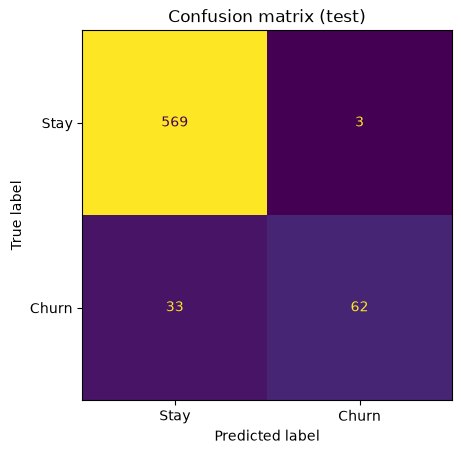

In [3]:
for metric in ["accuracy", "precision", "recall", "f1"]:
    s = cross_val_score(best, Xtr, y_train, cv=cv, scoring=metric)
    print("CV %-9s %.3f (+/- %.3f)" % (metric, s.mean(), s.std()))

pred = best.predict(Xte)
print("\nTest set:")
print(classification_report(y_test, pred, target_names=["Stay", "Churn"]))
print("Test ROC AUC: %.3f" % roc_auc_score(y_test, best.predict_proba(Xte)[:, 1]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Churn"]).plot(colorbar=False)
plt.title("Confusion matrix (test)"); plt.show()

**What this means:** The cross-validation scores (mean and spread over 5 folds) show how stable the model is on data it was not trained on. The test set is a final, one-time check. Compare **recall** (churners caught) with the logistic regression model, where it was very low; the confusion matrix shows exactly how many churners are caught and missed.

## Step 4: Feature importance

Total day minutes         0.238
Customer service calls    0.123
Total eve minutes         0.100
International plan_Yes    0.092
Total intl minutes        0.078
Total intl calls          0.064
Total night minutes       0.060
Total day calls           0.047


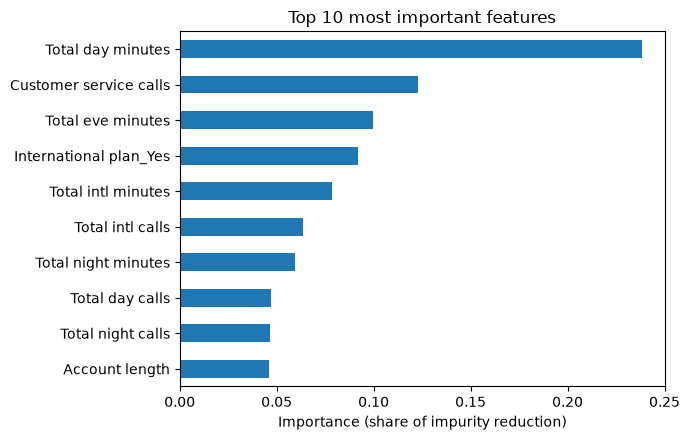

In [4]:
imp = pd.Series(best.feature_importances_, index=names).sort_values()
print(imp.sort_values(ascending=False).head(8).round(3).to_string())
imp.tail(10).plot.barh(figsize=(7, 4.5), color="tab:blue")
plt.title("Top 10 most important features"); plt.xlabel("Importance (share of impurity reduction)")
plt.tight_layout(); plt.show()

**What this means:** Importance shows how much each feature helps the trees make good splits (values add up to 1). It tells you what the model relies on, not the direction of the effect, and it can favour features with many distinct values. Use it as a guide and not as proof of cause.

## Conclusion
- A tuned Random Forest was trained and checked with 5-fold cross-validation and a held-out test set.
- Precision, recall and F1 are reported for churn specifically, since accuracy alone is misleading on imbalanced data.
- Feature importance shows which customer attributes the model depends on most.
- Next steps: try `class_weight="balanced"`, adjust the decision threshold, or compare with gradient boosting.